<a href="https://colab.research.google.com/github/geetanjali-scoriant/Week1_Machine_Learning_Fundamentals/blob/main/Week1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

DAY1

In [5]:
!mamba install pandas matplotlib seaborn
!mamba install scikit-learn


/bin/bash: line 1: mamba: command not found
/bin/bash: line 1: mamba: command not found


In [58]:
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.tree import DecisionTreeClassifier, plot_tree

In [7]:
movies = pd.read_csv("Movies (2) (1).csv")
movies

,color,director_name,num_critic_for_reviews,duration,director_facebook_likes,actor_3_facebook_likes,actor_2_name,actor_1_facebook_likes,gross,genres,...,num_user_for_reviews,language,country,content_rating,budget,title_year,actor_2_facebook_likes,imdb_score,aspect_ratio,movie_facebook_likes
0,Color,James Cameron,723.0,178.0,0.0,855.0,Joel David Moore,1000.0,760505847.0,Action|Adventure|Fantasy|Sci-Fi,...,3054.0,English,USA,PG-13,237000000.0,2009.0,936.0,7.9,1.78,33000
1,Color,Gore Verbinski,302.0,169.0,563.0,1000.0,Orlando Bloom,40000.0,309404152.0,Action|Adventure|Fantasy,...,1238.0,English,USA,PG-13,300000000.0,2007.0,5000.0,7.1,2.35,0
2,Color,Sam Mendes,602.0,148.0,0.0,161.0,Rory Kinnear,11000.0,200074175.0,Action|Adventure|Thriller,...,994.0,English,UK,PG-13,245000000.0,2015.0,393.0,6.8,2.35,85000
3,Color,Christopher Nolan,813.0,164.0,22000.0,23000.0,Christian Bale,27000.0,448130642.0,Action|Thriller,...,2701.0,English,USA,PG-13,250000000.0,2012.0,23000.0,8.5,2.35,164000
4,Color,Andrew Stanton,462.0,132.0,475.0,530.0,Samantha Morton,640.0,73058679.0,Action|Adventure|Sci-Fi,...,738.0,English,USA,PG-13,263700000.0,2012.0,632.0,6.6,2.35,24000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3848,Color,Shane Carruth,143.0,77.0,291.0,8.0,David Sullivan,291.0,424760.0,Drama|Sci-Fi|Thriller,...,371.0,English,USA,PG-13,7000.0,2004.0,45.0,7.0,1.85,19000
3849,Color,Neill Dela Llana,35.0,80.0,0.0,0.0,Edgar Tancangco,0.0,70071.0,Thriller,...,35.0,English,Philippines,Not Rated,7000.0,2005.0,0.0,6.3,NaN,74
3850,Color,Robert Rodriguez,56.0,81.0,0.0,6.0,Peter Marquardt,121.0,2040920.0,Action|Crime|Drama|Romance|Thriller,...,130.0,Spanish,USA,R,7000.0,1992.0,20.0,6.9,1.37,0
3851,Color,Edward Burns,14.0,95.0,0.0,133.0,Caitlin FitzGerald,296.0,4584.0,Comedy|Drama,...,14.0,English,USA,Not Rated,9000.0,2011.0,205.0,6.4,NaN,413


In [8]:
movies.shape

(3853, 28)

In [9]:
movies.columns[movies.isna().any()].tolist()

['color',
 'num_critic_for_reviews',
 'duration',
 'actor_3_facebook_likes',
 'actor_2_name',
 'actor_3_name',
 'facenumber_in_poster',
 'plot_keywords',
 'language',
 'content_rating',
 'actor_2_facebook_likes',
 'aspect_ratio']

In [10]:
print((movies.isnull().sum()>0).sum())

12


In [11]:
movies.columns.size

28

In [12]:
data = movies.drop(['color', 'director_facebook_likes', 'actor_1_facebook_likes', 'actor_2_facebook_likes', 'actor_3_facebook_likes',
                   'actor_2_name', 'cast_total_facebook_likes', 'actor_3_name', 'duration', 'facenumber_in_poster',
                   'content_rating', 'country', 'movie_imdb_link', 'aspect_ratio', 'plot_keywords'], axis = 1)
data.shape

(3853, 13)

In [13]:
percent_missing = data.isnull().sum() * 100 / len(data)
missing_value_df = pd.DataFrame({'column_name': data.columns,
                                 'percent_missing': percent_missing})
missing_value_df

,column_name,percent_missing
director_name,director_name,0.000000
num_critic_for_reviews,num_critic_for_reviews,0.025954
gross,gross,0.000000
genres,genres,0.000000
actor_1_name,actor_1_name,0.000000
movie_title,movie_title,0.000000
num_voted_users,num_voted_users,0.000000
num_user_for_reviews,num_user_for_reviews,0.000000
language,language,0.103815
budget,budget,0.000000


In [14]:
data.describe()

,num_critic_for_reviews,gross,num_voted_users,num_user_for_reviews,budget,title_year,imdb_score,movie_facebook_likes
count,3852.000000,3.853000e+03,3.853000e+03,3853.000000,3.853000e+03,3853.000000,3853.000000,3853.000000
mean,163.046989,5.096547e+07,1.024240e+05,326.720478,4.524817e+07,2003.061511,6.462886,9089.546068
std,123.927258,6.932033e+07,1.502942e+05,407.920904,2.234208e+08,10.007168,1.053843,21277.375223
min,1.000000,1.620000e+02,5.000000e+00,1.000000,2.180000e+02,1920.000000,1.600000,0.000000
25%,72.000000,6.830957e+06,1.730900e+04,102.000000,1.000000e+07,1999.000000,5.900000,0.000000
50%,134.000000,2.790000e+07,5.052300e+04,203.000000,2.400000e+07,2005.000000,6.600000,206.000000
75%,221.000000,6.550000e+07,1.241850e+05,391.000000,5.000000e+07,2010.000000,7.200000,11000.000000
max,813.000000,7.605058e+08,1.689764e+06,5060.000000,1.221550e+10,2016.000000,9.300000,349000.000000


In [15]:
data.info

<bound method DataFrame.info of           director_name  num_critic_for_reviews        gross  \
0         James Cameron                   723.0  760505847.0   
1        Gore Verbinski                   302.0  309404152.0   
2            Sam Mendes                   602.0  200074175.0   
3     Christopher Nolan                   813.0  448130642.0   
4        Andrew Stanton                   462.0   73058679.0   
...                 ...                     ...          ...   
3848      Shane Carruth                   143.0     424760.0   
3849   Neill Dela Llana                    35.0      70071.0   
3850   Robert Rodriguez                    56.0    2040920.0   
3851       Edward Burns                    14.0       4584.0   
3852           Jon Gunn                    43.0      85222.0   

                                   genres     actor_1_name  \
0         Action|Adventure|Fantasy|Sci-Fi      CCH Pounder   
1                Action|Adventure|Fantasy      Johnny Depp   
2               Action|Adventure|Thriller  Christoph Waltz   
3                         Action|Thriller        Tom Hardy   
4                 Action|Adventure|Sci-Fi     Daryl Sabara   
...                                   ...              ...   
3848                Drama|Sci-Fi|Thriller    Shane Carruth   
3849                             Thriller      Ian Gamazon   
3850  Action|Crime|Drama|Romance|Thriller  Carlos Gallardo   
3851                         Comedy|Drama      Kerry Bishé   
3852                          Documentary      John August   

                                    movie_title  num_voted_users  \
0                                       Avatar            886204   
1     Pirates of the Caribbean: At World's End            471220   
2                                      Spectre            275868   
3                        The Dark Knight Rises           1144337   
4                                  John Carter            212204   
...                                         ...              ...   
3848                                    Primer             72639   
3849                                    Cavite               589   
3850                               El Mariachi             52055   
3851                                 Newlyweds              1338   
3852                         My Date with Drew              4285   

      num_user_for_reviews language       budget  title_year  imdb_score  \
0                   3054.0  English  237000000.0      2009.0         7.9   
1                   1238.0  English  300000000.0      2007.0         7.1   
2                    994.0  English  245000000.0      2015.0         6.8   
3                   2701.0  English  250000000.0      2012.0         8.5   
4                    738.0  English  263700000.0      2012.0         6.6   
...                    ...      ...          ...         ...         ...   
3848                 371.0  English       7000.0      2004.0         7.0   
3849                  35.0  English       7000.0      2005.0         6.3   
3850                 130.0  Spanish       7000.0      1992.0         6.9   
3851                  14.0  English       9000.0      2011.0         6.4   
3852                  84.0  English       1100.0      2004.0         6.6   

      movie_facebook_likes  
0                    33000  
1                        0  
2                    85000  
3                   164000  
4                    24000  
...                    ...  
3848                 19000  
3849                    74  
3850                     0  
3851                   413  
3852                   456  

[3853 rows x 13 columns]>

In [16]:
data.head(5)

,director_name,num_critic_for_reviews,gross,genres,actor_1_name,movie_title,num_voted_users,num_user_for_reviews,language,budget,title_year,imdb_score,movie_facebook_likes
0,James Cameron,723.0,760505847.0,Action|Adventure|Fantasy|Sci-Fi,CCH Pounder,Avatar,886204,3054.0,English,237000000.0,2009.0,7.9,33000
1,Gore Verbinski,302.0,309404152.0,Action|Adventure|Fantasy,Johnny Depp,Pirates of the Caribbean: At World's End,471220,1238.0,English,300000000.0,2007.0,7.1,0
2,Sam Mendes,602.0,200074175.0,Action|Adventure|Thriller,Christoph Waltz,Spectre,275868,994.0,English,245000000.0,2015.0,6.8,85000
3,Christopher Nolan,813.0,448130642.0,Action|Thriller,Tom Hardy,The Dark Knight Rises,1144337,2701.0,English,250000000.0,2012.0,8.5,164000
4,Andrew Stanton,462.0,73058679.0,Action|Adventure|Sci-Fi,Daryl Sabara,John Carter,212204,738.0,English,263700000.0,2012.0,6.6,24000


In [17]:
movies['language']

,language
0,English
1,English
2,English
3,English
4,English
...,...
3848,English
3849,English
3850,Spanish
3851,English


In [18]:
movies['profit'] = movies['gross'] - movies['budget']

In [19]:
movies = movies.sort_values(by=['profit'], ascending=False, ignore_index=True)


In [20]:
top10 = movies.loc[0:9,'movie_title']
top10

,movie_title
0,Avatar
1,Jurassic World
2,Titanic
3,Star Wars: Episode IV - A New Hope
4,E.T. the Extra-Terrestrial
5,The Avengers
6,The Lion King
7,Star Wars: Episode I - The Phantom Menace
8,The Dark Knight
9,The Hunger Games


In [21]:
movies.head(5)

,color,director_name,num_critic_for_reviews,duration,director_facebook_likes,actor_3_facebook_likes,actor_2_name,actor_1_facebook_likes,gross,genres,...,language,country,content_rating,budget,title_year,actor_2_facebook_likes,imdb_score,aspect_ratio,movie_facebook_likes,profit
0,Color,James Cameron,723.0,178.0,0.0,855.0,Joel David Moore,1000.0,760505847.0,Action|Adventure|Fantasy|Sci-Fi,...,English,USA,PG-13,237000000.0,2009.0,936.0,7.9,1.78,33000,523505847.0
1,Color,Colin Trevorrow,644.0,124.0,365.0,1000.0,Judy Greer,3000.0,652177271.0,Action|Adventure|Sci-Fi|Thriller,...,English,USA,PG-13,150000000.0,2015.0,2000.0,7.0,2.00,150000,502177271.0
2,Color,James Cameron,315.0,194.0,0.0,794.0,Kate Winslet,29000.0,658672302.0,Drama|Romance,...,English,USA,PG-13,200000000.0,1997.0,14000.0,7.7,2.35,26000,458672302.0
3,Color,George Lucas,282.0,125.0,0.0,504.0,Peter Cushing,11000.0,460935665.0,Action|Adventure|Fantasy|Sci-Fi,...,English,USA,PG,11000000.0,1977.0,1000.0,8.7,2.35,33000,449935665.0
4,Color,Steven Spielberg,215.0,120.0,14000.0,548.0,Dee Wallace,861.0,434949459.0,Family|Sci-Fi,...,English,USA,PG,10500000.0,1982.0,725.0,7.9,1.85,34000,424449459.0


In [22]:
IMDb_Top_250 = movies.sort_values(by = 'imdb_score', ascending = False)

IMDb_Top_250 = IMDb_Top_250.loc[IMDb_Top_250.num_voted_users > 25000]
IMDb_Top_250 = IMDb_Top_250.iloc[:250, ]
IMDb_Top_250['Rank'] = range(1,251)

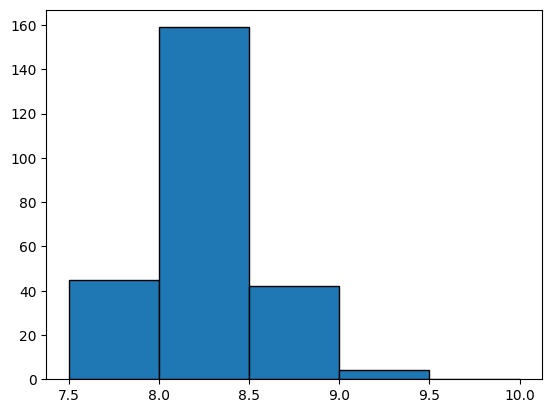

In [23]:
import matplotlib.pyplot as plt
plt.hist(IMDb_Top_250['imdb_score'], bins = 5, range = (7.5,10), edgecolor = 'black')
plt.show()

In [24]:
IMDb_Top_250['movie_title']

,movie_title
1744,The Shawshank Redemption
138,The Godfather
8,The Dark Knight
604,The Godfather: Part II
347,Schindler's List
...,...
3271,The World's Fastest Indian
2030,Moon
2082,Nine Queens
805,How to Train Your Dragon 2


In [25]:
#Scenario A: Predicting Box Office Success (Regression)

In [26]:
# Example code separating Input Features (X) and Target Variable (y) for Box Office Prediction
feature_cols = [
    'budget', 'duration', 'director_facebook_likes',
    'cast_total_facebook_likes', 'movie_facebook_likes', 'title_year'
]

model_df = movies[feature_cols + ['gross']].dropna()

X = model_df[feature_cols]  # Input Features
y = model_df['gross']       # Target Variable

print("Features (X) shape:", X.shape)
print("Target (y) shape:", y.shape)


Features (X) shape: (3852, 6)
Target (y) shape: (3852,)


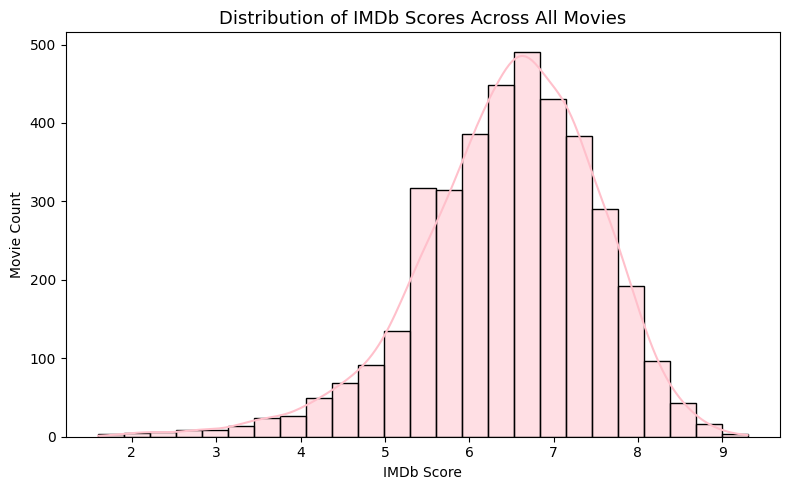

In [27]:
plt.figure(figsize=(8, 5))
sns.histplot(data=movies, x='imdb_score', bins=25, kde=True, color='pink')
plt.title('Distribution of IMDb Scores Across All Movies', fontsize=13)
plt.xlabel('IMDb Score')
plt.ylabel('Movie Count')
plt.tight_layout()
plt.show()

#Short notes explaining supervised and unsupervised learning with examples.

• Definition: A machine learning approach where the model is trained on a labeled dataset—meaning every input (X) comes
  paired with the correct output (y). The algorithm learns the mapping between inputs and outputs so it can predict answers for new,
  unseen data.
• Key Types:
	• Regression: Predicts a continuous numerical value (e.g., predicting box office gross revenue or house prices).
	• Classification: Predicts a discrete category or label (e.g., classifying emails as "Spam" vs. "Not Spam",
      or predicting whether a movie is a "Hit" vs. "Flop").
• Real-World & Movie Dataset Examples:
	• Predicting a movie's gross revenue (y) from its budget and duration (X).
	• Diagnosing medical images as "Healthy" or "Diseased".
	• Forecasting tomorrow's temperature based on historical weather data.

#DAY2

Label Encoding

In [28]:
Categorical_cols=['color','language','content_rating']

In [29]:
df_encoded=pd.get_dummies(movies,columns=Categorical_cols,dtype=int)

In [30]:
df_encoded

,director_name,num_critic_for_reviews,duration,director_facebook_likes,actor_3_facebook_likes,actor_2_name,actor_1_facebook_likes,gross,genres,actor_1_name,...,content_rating_GP,content_rating_M,content_rating_NC-17,content_rating_Not Rated,content_rating_PG,content_rating_PG-13,content_rating_Passed,content_rating_R,content_rating_Unrated,content_rating_X
0,James Cameron,723.0,178.0,0.0,855.0,Joel David Moore,1000.0,760505847.0,Action|Adventure|Fantasy|Sci-Fi,CCH Pounder,...,0,0,0,0,0,1,0,0,0,0
1,Colin Trevorrow,644.0,124.0,365.0,1000.0,Judy Greer,3000.0,652177271.0,Action|Adventure|Sci-Fi|Thriller,Bryce Dallas Howard,...,0,0,0,0,0,1,0,0,0,0
2,James Cameron,315.0,194.0,0.0,794.0,Kate Winslet,29000.0,658672302.0,Drama|Romance,Leonardo DiCaprio,...,0,0,0,0,0,1,0,0,0,0
3,George Lucas,282.0,125.0,0.0,504.0,Peter Cushing,11000.0,460935665.0,Action|Adventure|Fantasy|Sci-Fi,Harrison Ford,...,0,0,0,0,1,0,0,0,0,0
4,Steven Spielberg,215.0,120.0,14000.0,548.0,Dee Wallace,861.0,434949459.0,Family|Sci-Fi,Henry Thomas,...,0,0,0,0,1,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3848,Katsuhiro Ôtomo,105.0,103.0,78.0,101.0,Robin Atkin Downes,488.0,410388.0,Action|Adventure|Animation|Family|Sci-Fi|Thriller,William Hootkins,...,0,0,0,0,0,1,0,0,0,0
3849,Hayao Miyazaki,174.0,134.0,6000.0,745.0,Jada Pinkett Smith,893.0,2298191.0,Adventure|Animation|Fantasy,Minnie Driver,...,0,0,0,0,0,1,0,0,0,0
3850,Lajos Koltai,73.0,134.0,45.0,0.0,Péter Fancsikai,9.0,195888.0,Drama|Romance|War,Marcell Nagy,...,0,0,0,0,0,0,0,1,0,0
3851,Chan-wook Park,202.0,112.0,0.0,38.0,Yeong-ae Lee,717.0,211667.0,Crime|Drama,Min-sik Choi,...,0,0,0,0,0,0,0,1,0,0


In [31]:
df_encoded = movies.copy()

for col in Categorical_cols:

    le = LabelEncoder()

    df_encoded[col] = le.fit_transform(
        df_encoded[col]
    )



In [32]:
df_encoded.head()

,color,director_name,num_critic_for_reviews,duration,director_facebook_likes,actor_3_facebook_likes,actor_2_name,actor_1_facebook_likes,gross,genres,...,language,country,content_rating,budget,title_year,actor_2_facebook_likes,imdb_score,aspect_ratio,movie_facebook_likes,profit
0,1,James Cameron,723.0,178.0,0.0,855.0,Joel David Moore,1000.0,760505847.0,Action|Adventure|Fantasy|Sci-Fi,...,10,USA,7,237000000.0,2009.0,936.0,7.9,1.78,33000,523505847.0
1,1,Colin Trevorrow,644.0,124.0,365.0,1000.0,Judy Greer,3000.0,652177271.0,Action|Adventure|Sci-Fi|Thriller,...,10,USA,7,150000000.0,2015.0,2000.0,7.0,2.00,150000,502177271.0
2,1,James Cameron,315.0,194.0,0.0,794.0,Kate Winslet,29000.0,658672302.0,Drama|Romance,...,10,USA,7,200000000.0,1997.0,14000.0,7.7,2.35,26000,458672302.0
3,1,George Lucas,282.0,125.0,0.0,504.0,Peter Cushing,11000.0,460935665.0,Action|Adventure|Fantasy|Sci-Fi,...,10,USA,6,11000000.0,1977.0,1000.0,8.7,2.35,33000,449935665.0
4,1,Steven Spielberg,215.0,120.0,14000.0,548.0,Dee Wallace,861.0,434949459.0,Family|Sci-Fi,...,10,USA,6,10500000.0,1982.0,725.0,7.9,1.85,34000,424449459.0


In [33]:
min_max = MinMaxScaler()
df_encoded['budget_normalized'] = min_max.fit_transform(movies[['budget']])

In [34]:
df_encoded['budget_normalized']

,budget_normalized
0,0.019402
1,0.012279
2,0.016373
3,0.000900
4,0.000860
...,...
3848,0.174166
3849,0.196472
3850,0.204658
3851,0.343825


In [35]:
df_encoded

,color,director_name,num_critic_for_reviews,duration,director_facebook_likes,actor_3_facebook_likes,actor_2_name,actor_1_facebook_likes,gross,genres,...,country,content_rating,budget,title_year,actor_2_facebook_likes,imdb_score,aspect_ratio,movie_facebook_likes,profit,budget_normalized
0,1,James Cameron,723.0,178.0,0.0,855.0,Joel David Moore,1000.0,760505847.0,Action|Adventure|Fantasy|Sci-Fi,...,USA,7,2.370000e+08,2009.0,936.0,7.9,1.78,33000,5.235058e+08,0.019402
1,1,Colin Trevorrow,644.0,124.0,365.0,1000.0,Judy Greer,3000.0,652177271.0,Action|Adventure|Sci-Fi|Thriller,...,USA,7,1.500000e+08,2015.0,2000.0,7.0,2.00,150000,5.021773e+08,0.012279
2,1,James Cameron,315.0,194.0,0.0,794.0,Kate Winslet,29000.0,658672302.0,Drama|Romance,...,USA,7,2.000000e+08,1997.0,14000.0,7.7,2.35,26000,4.586723e+08,0.016373
3,1,George Lucas,282.0,125.0,0.0,504.0,Peter Cushing,11000.0,460935665.0,Action|Adventure|Fantasy|Sci-Fi,...,USA,6,1.100000e+07,1977.0,1000.0,8.7,2.35,33000,4.499357e+08,0.000900
4,1,Steven Spielberg,215.0,120.0,14000.0,548.0,Dee Wallace,861.0,434949459.0,Family|Sci-Fi,...,USA,6,1.050000e+07,1982.0,725.0,7.9,1.85,34000,4.244495e+08,0.000860
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3848,1,Katsuhiro Ôtomo,105.0,103.0,78.0,101.0,Robin Atkin Downes,488.0,410388.0,Action|Adventure|Animation|Family|Sci-Fi|Thriller,...,Japan,7,2.127520e+09,2004.0,336.0,6.9,1.85,973,-2.127110e+09,0.174166
3849,1,Hayao Miyazaki,174.0,134.0,6000.0,745.0,Jada Pinkett Smith,893.0,2298191.0,Adventure|Animation|Fantasy,...,Japan,7,2.400000e+09,1997.0,851.0,8.4,1.85,11000,-2.397702e+09,0.196472
3850,1,Lajos Koltai,73.0,134.0,45.0,0.0,Péter Fancsikai,9.0,195888.0,Drama|Romance|War,...,Hungary,9,2.500000e+09,2005.0,2.0,7.1,2.35,607,-2.499804e+09,0.204658
3851,1,Chan-wook Park,202.0,112.0,0.0,38.0,Yeong-ae Lee,717.0,211667.0,Crime|Drama,...,South Korea,9,4.200000e+09,2005.0,126.0,7.7,2.35,4000,-4.199788e+09,0.343825


TRAIN TEST SPLIT

Data leakage happens when information from outside the training dataset (such as the test set or future data)
accidentally "leaks" into your model during training.
This gives your model an unfair advantage during testing,
making it look much more accurate than it will actually be on real, unseen data.

• Fake High Accuracy: Your model gets great scores on X_test because it indirectly"peeked" at the answers.
• Fails in Production: When you give the model brand-new movies in the real world,
its predictions fall apart because those leaked hints are no longer there.

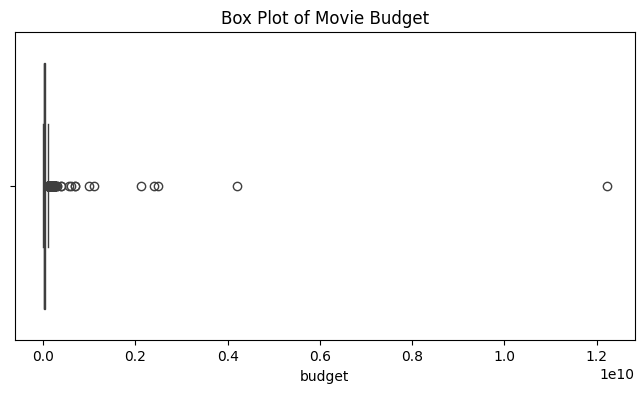

In [36]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=movies['budget'])
plt.title('Box Plot of Movie Budget')
plt.show()

In [37]:
movies['budget'].describe()

,budget
count,3.853000e+03
mean,4.524817e+07
std,2.234208e+08
min,2.180000e+02
25%,1.000000e+07
50%,2.400000e+07
75%,5.000000e+07
max,1.221550e+10


In [38]:
movies = pd.read_csv('Movies (2) (1).csv')
movies = movies[movies['country'] == 'USA']

In [40]:
movies.nlargest(10, 'budget')

,color,director_name,num_critic_for_reviews,duration,director_facebook_likes,actor_3_facebook_likes,actor_2_name,actor_1_facebook_likes,gross,genres,...,num_user_for_reviews,language,country,content_rating,budget,title_year,actor_2_facebook_likes,imdb_score,aspect_ratio,movie_facebook_likes
1,Color,Gore Verbinski,302.0,169.0,563.0,1000.0,Orlando Bloom,40000.0,309404152.0,Action|Adventure|Fantasy,...,1238.0,English,USA,PG-13,300000000.0,2007.0,5000.0,7.1,2.35,0
4,Color,Andrew Stanton,462.0,132.0,475.0,530.0,Samantha Morton,640.0,73058679.0,Action|Adventure|Sci-Fi,...,738.0,English,USA,PG-13,263700000.0,2012.0,632.0,6.6,2.35,24000
6,Color,Nathan Greno,324.0,100.0,15.0,284.0,Donna Murphy,799.0,200807262.0,Adventure|Animation|Comedy|Family|Fantasy|Musi...,...,387.0,English,USA,PG,260000000.0,2010.0,553.0,7.8,1.85,29000
5,Color,Sam Raimi,392.0,156.0,0.0,4000.0,James Franco,24000.0,336530303.0,Action|Adventure|Romance,...,1902.0,English,USA,PG-13,258000000.0,2007.0,11000.0,6.2,2.35,0
3012,Color,Sam Raimi,392.0,156.0,0.0,4000.0,James Franco,24000.0,336530303.0,Action|Adventure|Romance,...,1902.0,English,USA,PG-13,258000000.0,2007.0,11000.0,6.2,2.35,0
3,Color,Christopher Nolan,813.0,164.0,22000.0,23000.0,Christian Bale,27000.0,448130642.0,Action|Thriller,...,2701.0,English,USA,PG-13,250000000.0,2012.0,23000.0,8.5,2.35,164000
7,Color,Joss Whedon,635.0,141.0,0.0,19000.0,Robert Downey Jr.,26000.0,458991599.0,Action|Adventure|Sci-Fi,...,1117.0,English,USA,PG-13,250000000.0,2015.0,21000.0,7.5,2.35,118000
9,Color,Zack Snyder,673.0,183.0,0.0,2000.0,Lauren Cohan,15000.0,330249062.0,Action|Adventure|Sci-Fi,...,3018.0,English,USA,PG-13,250000000.0,2016.0,4000.0,6.9,2.35,197000
17,Color,Rob Marshall,448.0,136.0,252.0,1000.0,Sam Claflin,40000.0,241063875.0,Action|Adventure|Fantasy,...,484.0,English,USA,PG-13,250000000.0,2011.0,11000.0,6.7,2.35,58000
26,Color,Anthony Russo,516.0,147.0,94.0,11000.0,Scarlett Johansson,21000.0,407197282.0,Action|Adventure|Sci-Fi,...,1022.0,English,USA,PG-13,250000000.0,2016.0,19000.0,8.2,2.35,72000


In [41]:
movies.groupby('country')['budget'].median().sort_values(ascending=False)

,budget
country,
USA,25000000.0


In [42]:
X = movies[['budget']]
y = movies['gross']

Slope (coefficient): 1.0723787341390254
Intercept: 14660587.282744281
MAE:  35264128.402207434
RMSE: 57848995.9039612
R²:   0.3804936471697252


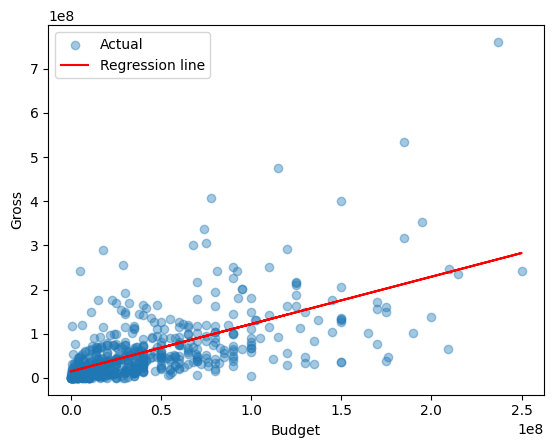

In [43]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

# 4. Train
model = LinearRegression()
model.fit(X_train, y_train)

# 5. Predict and evaluate
y_pred = model.predict(X_test)

print("Slope (coefficient):", model.coef_[0])
print("Intercept:", model.intercept_)
print("MAE: ", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R²:  ", r2_score(y_test, y_pred))

# 6. Plot
plt.scatter(X_test, y_test, alpha=0.4, label='Actual')
plt.plot(X_test, y_pred, color='red', label='Regression line')
plt.xlabel('Budget')
plt.ylabel('Gross')
plt.legend()
plt.show()

In [44]:
new_movie = pd.DataFrame({
    'budget': [50000000]
})

prediction = model.predict(new_movie)

print("Predicted Gross Revenue:", prediction[0])

Predicted Gross Revenue: 68279523.98969555


DAY 3: Supervised Machine Learning Algorithms

In [45]:
movies['hit_flop'] = (movies['gross'] > movies['budget']).astype(int)

features = ['budget', 'duration', 'title_year', 'imdb_score', 'num_voted_users', 'num_critic_for_reviews']

data = movies[features + ['hit_flop']].dropna()
X = data[features]
y = data['hit_flop']

In [46]:
movies['hit_flop'].value_counts()

,count
hit_flop,
1,1746
0,1300


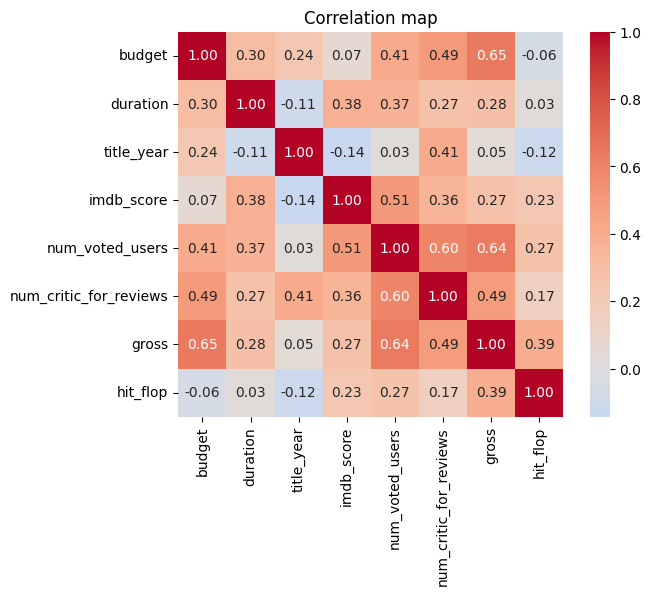

In [47]:
cols = ['budget', 'duration', 'title_year', 'imdb_score',
        'num_voted_users', 'num_critic_for_reviews', 'gross', 'hit_flop']

plt.figure(figsize=(7, 5))
sns.heatmap(movies[cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True)
plt.title('Correlation map')
plt.show()

In [48]:


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [49]:
from sklearn.preprocessing import StandardScaler

sc = StandardScaler()

X_train_scaled = sc.fit_transform(X_train)
X_test_scaled = sc.transform(X_test)

In [50]:


lr = LogisticRegression()

lr.fit(X_train_scaled, y_train)

y_pred = lr.predict(X_test_scaled)

In [51]:
print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.7323481116584565


In [52]:

print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

[[182  93]
 [ 70 264]]
              precision    recall  f1-score   support

           0       0.72      0.66      0.69       275
           1       0.74      0.79      0.76       334

    accuracy                           0.73       609
   macro avg       0.73      0.73      0.73       609
weighted avg       0.73      0.73      0.73       609



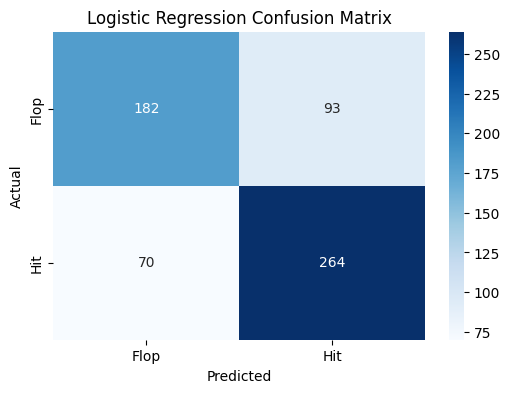

In [53]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Flop', 'Hit'],
    yticklabels=['Flop', 'Hit']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Logistic Regression Confusion Matrix')
plt.show()

In [54]:
hgb = HistGradientBoostingClassifier(
    learning_rate=0.05,   # how big each correction step is
    max_iter=300,         # number of trees (rounds)
    max_depth=4,          # keep each tree small
    min_samples_leaf=20,
    early_stopping=True,  # stop when it stops improving
    random_state=42
)
hgb.fit(X_train, y_train)
y_pred = hgb.predict(X_test)

print("Train accuracy:", round(hgb.score(X_train, y_train), 3))
print("Test accuracy: ", round(accuracy_score(y_test, y_pred), 3))
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=['Flop', 'Hit']))

Train accuracy: 0.814
Test accuracy:  0.727
[[189  86]
 [ 80 254]]
              precision    recall  f1-score   support

        Flop       0.70      0.69      0.69       275
         Hit       0.75      0.76      0.75       334

    accuracy                           0.73       609
   macro avg       0.72      0.72      0.72       609
weighted avg       0.73      0.73      0.73       609



In [55]:
#Random forest
rf = RandomForestClassifier(
    n_estimators=300,
    min_samples_leaf=5,
    max_features='sqrt',
    oob_score=True,
    random_state=42,
    n_jobs=1
)
rf.fit(X_train, y_train)
y_pred = rf.predict(X_test)

# 5. Results
print("Train accuracy:", round(rf.score(X_train, y_train), 3))
print("OOB accuracy:  ", round(rf.oob_score_, 3))
print("Test accuracy: ", round(accuracy_score(y_test, y_pred), 3))
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=['Flop', 'Hit']))

Train accuracy: 0.911
OOB accuracy:   0.739
Test accuracy:  0.718
[[184  91]
 [ 81 253]]
              precision    recall  f1-score   support

        Flop       0.69      0.67      0.68       275
         Hit       0.74      0.76      0.75       334

    accuracy                           0.72       609
   macro avg       0.71      0.71      0.71       609
weighted avg       0.72      0.72      0.72       609

